# Assignment: a VAE pipeline for your dataset

## Problem statement

In the lesson you saw a variational autoencoder built and trained on MNIST digits. In this assignment you build the same pipeline yourself, for a different dataset. Which dataset you get is decided by your name in section 0.

**Already implemented** (do not change these cells):

- section 0 picks your variant;
- section 1 downloads your dataset and converts it to the usable format;
- section 2 defines `show_images` and shows some training images;
- section 4 draws reconstructions, new generated images and a walk through the latent space.

**You implement** (section 3):

1. the class `VAE`, the architecture is your choice;
2. the function `vae_loss`;
3. the function `train`;
4. the last cell of section 3: choose the latent size `d`, build the model and train it.

### The interface your model must have

Section 4 uses your model only through the following, so keep the names, the shapes and the order of the outputs.

- `model.d` is the size of the latent vector.
- `model.encode(x)` takes `x` of shape `(batch, 784)` and returns `mu, logvar`, each of shape `(batch, d)`.
- `model.decode(z)` takes `z` of shape `(batch, d)` and returns `x_hat` of shape `(batch, 784)` with values in $[0, 1]$.
- `model(x)` returns `x_hat, z, mu, logvar`, where `z` is sampled with the reparameterization trick.

### Reminders from the lesson

- The loss is reconstruction $+ \beta \cdot$ KL, with $\beta = 1$ for the standard VAE.
- Both terms are measured **per image**: summed over the pixels (reconstruction) or over the latent dimensions (KL), then averaged over the batch.
- With $d = 2$ the results are blurry; a larger latent space gives better images.

### What a good result looks like

After training, run section 4 without changes. The reconstructions should be recognisable as the inputs, and most of the generated images should look like plausible members of your dataset (some blur is normal for VAE). Training should take a few minutes on a Colab GPU (Runtime -> Change runtime type -> T4 GPU). Experiment with your neural network architecture, $d$, and $\beta$ to get the best results.


## 0. Your variant

Write your name and run the cell. It will determine your variant. You do not need to change anything in section 1 regarding data read, it is pre-done for you after the `variant` variable is defined.

In [ ]:
NAME = "Daria Krichfalushy"   # <- your full name, as in the course list

VARIANTS = ["Fashion-MNIST", "KMNIST", "EMNIST Letters (A-J)"]

assert NAME.strip(), "Write your name in the first line of this cell"
variant = sum(ord(ch) for ch in NAME.lower() if ch.isalpha()) % len(VARIANTS)
print(f"{NAME}, your variant is {variant}: {VARIANTS[variant]}")

Daria Krichfalushy, your variant is 0: Fashion-MNIST


## 1. Data

This cell downloads your dataset and converts it to the format similar to the one used in the lesson:

- `x_train`, `x_test`: float tensors of shape `(N, 784)` with values in $[0, 1]$, one row = one flattened 28×28 image, already on `device`;
- `y_train`, `y_test`: integer labels from 0 to 9, only used for titles and plots; the model never sees them;
- `class_names`: the names of the 10 classes.

Few notes on datasets:

- **KMNIST** contains handwritten Japanese characters; `class_names` gives their readings.
- **EMNIST Letters** is a large download and takes a few minutes. Only the letters A to J are kept. Upper-case and lower-case letters share a class, so class `A` contains both "A" and "a".

In [ ]:
import torch, torch.nn as nn, torch.nn.functional as F
import numpy as np, matplotlib.pyplot as plt
from torchvision import datasets

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using", device)

if variant == 0:
    raw_train = datasets.FashionMNIST("data", train=True, download=True)
    raw_test = datasets.FashionMNIST("data", train=False, download=True)
    class_names = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat",
                   "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
elif variant == 1:
    raw_train = datasets.KMNIST("data", train=True, download=True)
    raw_test = datasets.KMNIST("data", train=False, download=True)
    class_names = ["o", "ki", "su", "tsu", "na", "ha", "ma", "ya", "re", "wo"]
else:
    raw_train = datasets.EMNIST("data", split="letters", train=True, download=True)
    raw_test = datasets.EMNIST("data", split="letters", train=False, download=True)
    class_names = list("ABCDEFGHIJ")


def to_tensors(raw):
    """torchvision dataset -> (x, y): x float (N, 784) in [0, 1] on device, y int (N,) on cpu."""
    x = raw.data.float().div(255)          # (N, 28, 28), values in [0, 1]
    y = raw.targets.clone()
    if variant == 2:
        x = x.transpose(1, 2)              # EMNIST images are stored transposed
        keep = (y >= 1) & (y <= 10)        # labels 1..26 mean a..z; keep a..j
        x, y = x[keep], y[keep] - 1        # relabel to 0..9
    return x.reshape(-1, 784).to(device), y


x_train, y_train = to_tensors(raw_train)
x_test, y_test = to_tensors(raw_test)

print("dataset:", VARIANTS[variant])
print("train:", tuple(x_train.shape), " test:", tuple(x_test.shape))
print("classes:", class_names)

Using cuda


100%|██████████| 26.4M/26.4M [00:01<00:00, 13.6MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 200kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.74MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 11.4MB/s]


dataset: Fashion-MNIST
train: (60000, 784)  test: (10000, 784)
classes: ['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


## 2. Looking at the data

`show_images` takes a list of tensors of shape `(n, 784)` and draws each one as a row of images. Section 4 reuses it, and you can use it too.

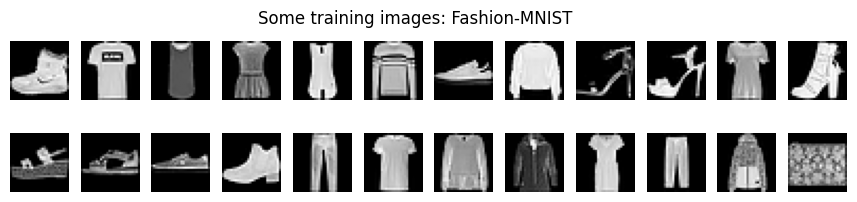

first row:  ['Ankle boot', 'T-shirt', 'T-shirt', 'Dress', 'T-shirt', 'Pullover', 'Sneaker', 'Pullover', 'Sandal', 'Sandal', 'T-shirt', 'Ankle boot']
second row: ['Sandal', 'Sandal', 'Sneaker', 'Ankle boot', 'Trouser', 'T-shirt', 'Shirt', 'Coat', 'Dress', 'Trouser', 'Coat', 'Bag']


In [ ]:
def show_images(rows, title=""):
    """rows: a list of tensors, each (n, 784). Shows each tensor as one row of images."""
    n = rows[0].shape[0]
    fig, axes = plt.subplots(len(rows), n, figsize=(n * 0.9, len(rows) * 0.9 + 0.4))
    axes = np.atleast_2d(axes)
    for r, imgs in enumerate(rows):
        for c in range(n):
            axes[r, c].imshow(imgs[c].detach().cpu().view(28, 28), cmap="gray", vmin=0, vmax=1)
            axes[r, c].axis("off")
    fig.suptitle(title)
    plt.show()


show_images([x_train[:12], x_train[12:24]], f"Some training images: {VARIANTS[variant]}")
print("first row: ", [class_names[int(i)] for i in y_train[:12]])
print("second row:", [class_names[int(i)] for i in y_train[12:24]])

## 3. The VAE and its training (your work)

Fill in the three cells below. You may add arguments with default values, extra methods and extra cells, as long as the interface from the problem statement stays intact.

In [9]:
class VAE(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.d = d
        # TODO: define the layers of the encoder and of the decoder
        # >>
        # Encoder: (1, 28, 28) -> conv -> (32, 14, 14) -> conv -> (64, 7, 7) -> 256 -> mu, logvar
        self.enc = nn.Sequential(
            nn.Conv2d(1, 32, 4, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, 4, stride=2, padding=1),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 256),
            nn.ReLU(),
        )
        self.fc_mu = nn.Linear(256, d)
        self.fc_logvar = nn.Linear(256, d)
        # Decoder: the mirror image, d -> 256 -> (64, 7, 7) -> (32, 14, 14) -> (1, 28, 28)
        self.dec = nn.Sequential(
            nn.Linear(d, 256),
            nn.ReLU(),
            nn.Linear(256, 64 * 7 * 7),
            nn.ReLU(),
            nn.Unflatten(1, (64, 7, 7)),
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 1, 4, stride=2, padding=1),
        )


    def encode(self, x):
        """x: (batch, 784) -> mu, logvar, each (batch, d)."""
        h = self.enc(x.view(-1, 1, 28, 28))
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar

    def decode(self, z):
        """z: (batch, d) -> x_hat: (batch, 784), values in [0, 1]."""
        x_hat = torch.sigmoid(self.dec(z)).view(-1, 784)
        return x_hat

    def forward(self, x):
        """x: (batch, 784) -> x_hat, z, mu, logvar (in this order).
        z is sampled with the reparameterization trick."""
        mu, logvar = self.encode(x)
        eps = torch.randn_like(mu)
        z = mu + torch.exp(0.5 * logvar) * eps  # z = mu + sigma * eps, eps ~ N(0, I)
        x_hat = self.decode(z)
        return x_hat, z, mu, logvar


In [10]:
def vae_loss(model, x, beta=1.0):
    """Reconstruction + beta * KL for the batch x, both terms per image.
    Returns one number (a scalar tensor)."""
    x_hat, z, mu, logvar = model(x)
    # Reconstruction: binary cross-entropy summed over the 784 pixels, averaged over the batch
    rec = F.binary_cross_entropy(x_hat, x, reduction="none").sum(dim=1).mean()
    kl = (-0.5 * (1 + logvar - mu.pow(2) - logvar.exp())).sum(dim=1).mean()
    loss = rec + beta * kl
    return loss


def train(model, epochs, batch_size=128, lr=1e-3, beta=1.0):
    """Trains the model on x_train and prints the loss on x_test after every epoch.
    Returns the trained model."""
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    n = len(x_train)

    for epoch in range(1, epochs+1):
      model.train()
      perm = torch.randperm(n, device=x_train.device)   # new shuffle every epoch
      total = 0.0
      for start in range(0, n, batch_size):
        xb = x_train[perm[start:start + batch_size]]
        loss = vae_loss(model, xb, beta)
        opt.zero_grad()
        loss.backward()
        opt.step()
        total += loss.item() * len(xb)

      # Loss on the test set, computed in batches without gradients
      model.eval()
      test_total = 0.0
      with torch.no_grad():
        for start in range(0, len(x_test), 1000):
          xb = x_test[start:start+1000]
          test_total += vae_loss(model, xb, beta).item() * len(xb)
      print(f"epoch {epoch:3d} / train loss {total / n:8.2f} / "
            f"test loss {test_total / len(x_test):8.2f}")

    return model


In [11]:
# TODO: choose d, build your model and train it
d = 16
vae = VAE(d)
vae = train(vae, epochs=30, batch_size=128, lr=1e-3, beta=1.0)

epoch   1 / train loss   283.67 / test loss   257.61
epoch   2 / train loss   250.20 / test loss   248.66
epoch   3 / train loss   245.48 / test loss   246.12
epoch   4 / train loss   243.27 / test loss   244.35
epoch   5 / train loss   241.83 / test loss   242.79
epoch   6 / train loss   240.78 / test loss   242.22
epoch   7 / train loss   239.99 / test loss   241.36
epoch   8 / train loss   239.33 / test loss   240.71
epoch   9 / train loss   238.85 / test loss   240.72
epoch  10 / train loss   238.45 / test loss   240.19
epoch  11 / train loss   238.07 / test loss   239.97
epoch  12 / train loss   237.78 / test loss   239.63
epoch  13 / train loss   237.52 / test loss   239.80
epoch  14 / train loss   237.32 / test loss   239.22
epoch  15 / train loss   237.12 / test loss   239.29
epoch  16 / train loss   236.93 / test loss   239.04
epoch  17 / train loss   236.72 / test loss   238.90
epoch  18 / train loss   236.55 / test loss   238.94
epoch  19 / train loss   236.45 / test loss   

## 4. Results

Run these cells without changes after training.

**Reconstructions.** Test images are encoded to their mean code $\mu$ and decoded back.

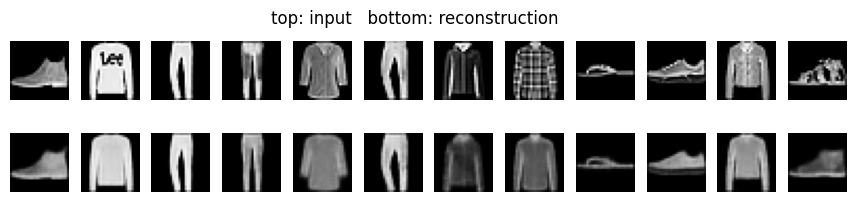

In [12]:
vae.eval()
with torch.no_grad():
    mu, logvar = vae.encode(x_test[:12])
    x_hat = vae.decode(mu)
show_images([x_test[:12], x_hat], "top: input   bottom: reconstruction")

**Generation.** New images: draw $z \sim \mathcal{N}(0, I)$ and decode.

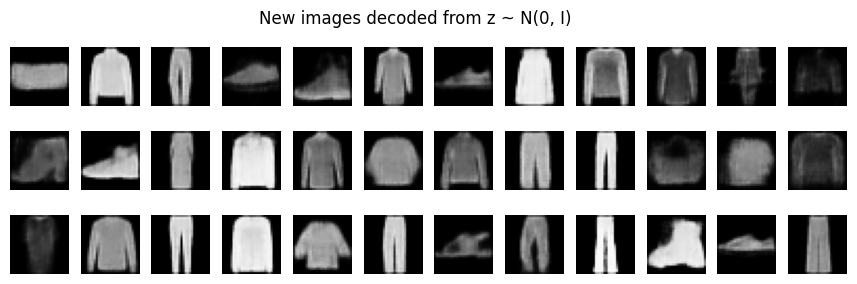

In [13]:
torch.manual_seed(0)
with torch.no_grad():
    z = torch.randn(36, vae.d, device=device)
    fake = vae.decode(z)
show_images([fake[:12], fake[12:24], fake[24:]], "New images decoded from z ~ N(0, I)")

**A walk through the latent space.** Take the codes of two test images of different classes and decode 12 evenly spaced points on the straight line between them.

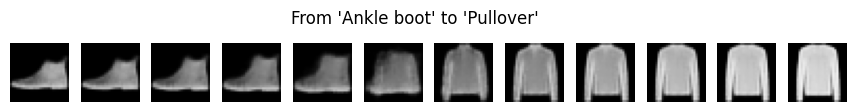

In [14]:
i = 0
j = int((y_test != y_test[i]).nonzero()[0])        # first test image of a different class
with torch.no_grad():
    mu, logvar = vae.encode(x_test[[i, j]])
    t = torch.linspace(0, 1, 12, device=device).unsqueeze(1)     # (12, 1)
    z = (1 - t) * mu[0] + t * mu[1]                              # (12, d)
    steps = vae.decode(z)
show_images([steps], f"From '{class_names[int(y_test[i])]}' to '{class_names[int(y_test[j])]}'")